# 04 - Sentiment vs. Stock Returns

## Purpose
Investigate whether **positive** and **negative** news sentiment is associated with **different stock returns**.

## Inputs (`data/processed/`)
- `news_articles_sentiment.csv` - one row per article with its FinBERT score (`finbert_score`, from -1 to +1)
- `news_tickers.csv` (v2) - one row per article-ticker pair, with `n_symbols_total` and `reaction_date`
- `market_clean.csv` - daily stock returns (`return`, `next_day_return`)

## Output
This notebook does not create a data file. Its output is the analysis: average returns per sentiment category, per-ticker monthly correlations, **three charts** and **five written findings**.

> **Important interpretation:** the same-day return (return on `reaction_date`) reflects the market's reaction to the news, while the next-day return helps investigate whether sentiment has any association with the **subsequent** movement. **Neither establishes causation.**

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROCESSED_DIR = Path("../../data/processed")

SENTIMENT_PATH = PROCESSED_DIR / "news_articles_sentiment.csv"
NEWS_TICKERS_PATH = PROCESSED_DIR / "news_tickers.csv"
MARKET_PATH = PROCESSED_DIR / "market_clean.csv"

CATEGORY_ORDER = ["Negative", "Neutral", "Positive"]
CATEGORY_COLORS = {"Negative": "#d62728", "Neutral": "#7f7f7f", "Positive": "#2ca02c"}

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## Step 1 - Load the data

In [2]:
sentiment = pd.read_csv(SENTIMENT_PATH, usecols=["article_id", "finbert_label", "finbert_score"])
news_tickers = pd.read_csv(NEWS_TICKERS_PATH, parse_dates=["reaction_date"])
market = pd.read_csv(MARKET_PATH, parse_dates=["date"])

print(f"news_articles_sentiment : {len(sentiment):,} articles (article_id unique: {sentiment['article_id'].is_unique})")
print(f"news_tickers (v2)       : {len(news_tickers):,} article-ticker rows, columns = {list(news_tickers.columns)}")
print(f"market_clean            : {len(market):,} rows, {market['ticker'].nunique()} tickers, "
      f"{market['date'].min().date()} -> {market['date'].max().date()}")

news_articles_sentiment : 79,549 articles (article_id unique: True)
news_tickers (v2)       : 102,767 article-ticker rows, columns = ['article_id', 'ticker', 'n_symbols_total', 'n_project_tickers', 'published_at', 'reaction_date']
market_clean            : 12,540 rows, 10 tickers, 2021-01-04 -> 2025-12-30


## Step 2 - Attach the same-day and next-day stock returns to every article-ticker row
- `same_day_return` = the stock's `return` on the article's `reaction_date`
- `next_day_return` = the stock's return on the **next trading day** (already stored in `market_clean.csv` as `next_day_return`)

In [3]:
rows = news_tickers.merge(sentiment[["article_id", "finbert_score"]], on="article_id", how="left", validate="many_to_one")
print(f"Rows without a FinBERT score: {rows['finbert_score'].isna().sum()}")

rows = rows.merge(
    market[["ticker", "date", "return", "next_day_return"]].rename(columns={"date": "reaction_date", "return": "same_day_return"}),
    on=["ticker", "reaction_date"],
    how="left",
    validate="many_to_one",
    indicator=True,
)
assert len(rows) == len(news_tickers)

no_price = rows["_merge"] != "both"
print(f"Rows whose reaction_date is not in market_clean: {no_price.sum()}")
print(rows.loc[no_price, "reaction_date"].dt.date.value_counts().sort_index().to_string())

Rows without a FinBERT score: 0
Rows whose reaction_date is not in market_clean: 56
reaction_date
2025-12-31    50
2026-01-02     6


The rows above are articles published after the last trading day in `market_clean.csv` (2025-12-30), so their reaction date (2025-12-31 or 2026-01-02) falls outside the price data and has no return. They are excluded from the return analysis.

In [4]:
rows = rows.loc[~no_price].drop(columns="_merge").reset_index(drop=True)

print(f"Article-ticker rows used: {len(rows):,}")
print(rows[["same_day_return", "next_day_return"]].isna().sum().to_string())
rows.head()

Article-ticker rows used: 102,711
same_day_return    56
next_day_return    39


,article_id,ticker,n_symbols_total,n_project_tickers,published_at,reaction_date,finbert_score,same_day_return,next_day_return
0,10903978,KO,5,1,2022-12-12 14:11:17+00:00,2022-12-12,0.010643,0.013145,0.000313
1,10978750,AAPL,1,1,2022-01-03 14:03:00+00:00,2022-01-03,-0.014750,0.025004,-0.012692
2,11007650,AAPL,3,1,2023-01-09 15:46:00+00:00,2023-01-09,0.023441,0.004089,0.004456
3,11013619,XOM,3,1,2022-01-10 14:19:00+00:00,2022-01-10,-0.032094,-0.005953,0.042062
4,11093651,AAPL,4,1,2021-01-29 14:04:00+00:00,2021-01-29,0.039499,-0.037420,0.016520


`next_day_return` is empty only where the reaction date is the last trading day (2025-12-30), because there is no next day in the data. Those rows are kept for the same-day analysis and skipped automatically in next-day averages.

## Step 3 - Categorise sentiment
| Category | Rule |
|---|---|
| Negative | `finbert_score` < -0.3 |
| Neutral | -0.3 <= `finbert_score` <= +0.3 |
| Positive | `finbert_score` > +0.3 |

In [5]:
rows["sentiment_category"] = np.select(
    [rows["finbert_score"] < -0.3, rows["finbert_score"] > 0.3],
    ["Negative", "Positive"],
    default="Neutral",
)
rows["sentiment_category"] = pd.Categorical(rows["sentiment_category"], categories=CATEGORY_ORDER, ordered=True)

counts = rows["sentiment_category"].value_counts().reindex(CATEGORY_ORDER)
print(pd.DataFrame({"rows": counts, "share_%": (counts / counts.sum() * 100).round(1)}).to_string())

                     rows  share_%
sentiment_category                
Negative            25178     24.5
Neutral             46189     45.0
Positive            31344     30.5


## Step 4 - Average returns per sentiment category
Two views:
- **All articles**
- **Focused articles** - only articles with `n_symbols_total` of **3 or fewer**. Articles that mention many symbols are usually market roundups, so their sentiment is less likely to be about the specific stock.

Returns are shown in **%**.

In [6]:
def category_returns(df):
    out = df.groupby("sentiment_category", observed=False).agg(
        rows=("same_day_return", "size"),
        avg_same_day_return=("same_day_return", "mean"),
        avg_next_day_return=("next_day_return", "mean"),
    )
    out[["avg_same_day_return", "avg_next_day_return"]] *= 100
    return out.round(4)

focused = rows[rows["n_symbols_total"] <= 3]

all_articles = category_returns(rows)
focused_articles = category_returns(focused)

print(f"ALL ARTICLES ({len(rows):,} rows) - returns in %")
print(all_articles.to_string())
print(f"\nFOCUSED ARTICLES, n_symbols_total <= 3 ({len(focused):,} rows) - returns in %")
print(focused_articles.to_string())

print("\nSpread Positive - Negative (percentage points):")
for name, t in [("All", all_articles), ("Focused", focused_articles)]:
    print(f"  {name:<8} same day {t.loc['Positive', 'avg_same_day_return'] - t.loc['Negative', 'avg_same_day_return']:+.4f} | "
          f"next day {t.loc['Positive', 'avg_next_day_return'] - t.loc['Negative', 'avg_next_day_return']:+.4f}")

print(f"\nFor reference - average daily return of all stock-days in market_clean: {market['return'].mean() * 100:.4f}%")

ALL ARTICLES (102,711 rows) - returns in %
                     rows  avg_same_day_return  avg_next_day_return
sentiment_category                                                 
Negative            25178              -0.1835               0.1249
Neutral             46189               0.1464               0.1064
Positive            31344               0.4958               0.0953

FOCUSED ARTICLES, n_symbols_total <= 3 (53,861 rows) - returns in %
                     rows  avg_same_day_return  avg_next_day_return
sentiment_category                                                 
Negative            13472              -0.2645               0.1101
Neutral             21542               0.0956               0.1141
Positive            18847               0.5483               0.1078

Spread Positive - Negative (percentage points):
  All      same day +0.6793 | next day -0.0296
  Focused  same day +0.8128 | next day -0.0023

For reference - average daily return of all stock-days in market

### Chart 1 - Average return by sentiment category

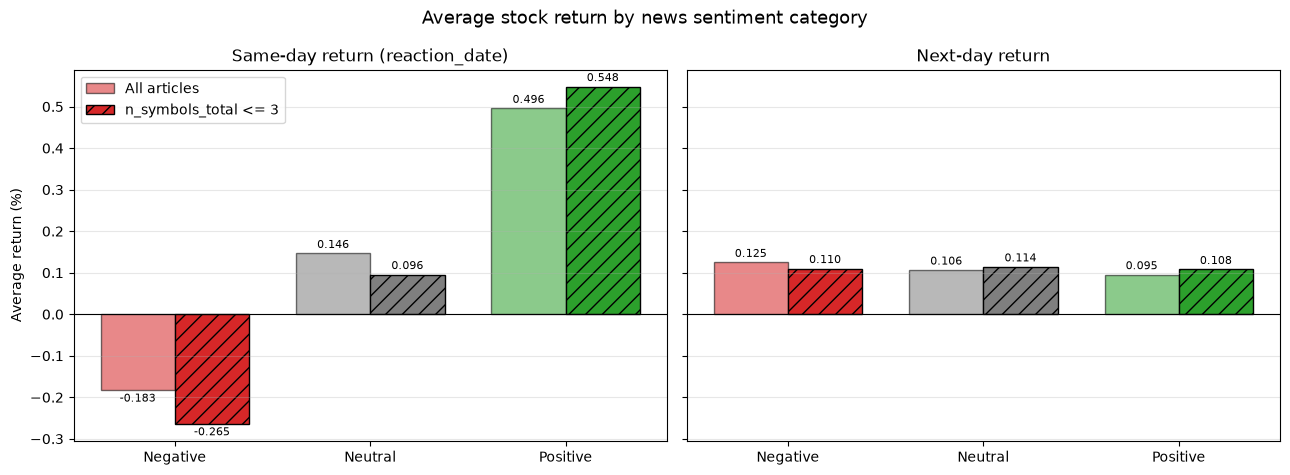

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
x = np.arange(len(CATEGORY_ORDER))
width = 0.38

for ax, col, title in [
    (axes[0], "avg_same_day_return", "Same-day return (reaction_date)"),
    (axes[1], "avg_next_day_return", "Next-day return"),
]:
    b1 = ax.bar(x - width / 2, all_articles[col], width, label="All articles",
                color=[CATEGORY_COLORS[c] for c in CATEGORY_ORDER], alpha=0.55, edgecolor="black")
    b2 = ax.bar(x + width / 2, focused_articles[col], width, label="n_symbols_total <= 3",
                color=[CATEGORY_COLORS[c] for c in CATEGORY_ORDER], edgecolor="black", hatch="//")
    for bars in (b1, b2):
        ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(x, CATEGORY_ORDER)
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.3)

axes[0].set_ylabel("Average return (%)")
axes[0].legend(loc="upper left")
fig.suptitle("Average stock return by news sentiment category", fontsize=13)
plt.tight_layout()
plt.show()

## Step 5 - Per-ticker correlation: monthly average sentiment vs. monthly stock return
- **Monthly average sentiment** = mean `finbert_score` of all article-ticker rows of that ticker whose `reaction_date` falls in the month.
- **Monthly stock return** = compounded daily returns within the month: $\prod (1 + r_t) - 1$.
- Correlation = Pearson correlation across the months of each ticker (60 months, Jan 2021 - Dec 2025).

In [8]:
monthly_sentiment = (
    rows.assign(month=rows["reaction_date"].dt.to_period("M"))
    .groupby(["ticker", "month"])
    .agg(avg_sentiment=("finbert_score", "mean"), n_articles=("finbert_score", "size"))
)

monthly_return = (
    market.assign(month=market["date"].dt.to_period("M"))
    .groupby(["ticker", "month"])["return"]
    .apply(lambda r: (1 + r.dropna()).prod() - 1)
    .rename("monthly_return")
)

monthly = monthly_sentiment.join(monthly_return, how="inner").reset_index()
print(f"Ticker-months: {len(monthly)} | months per ticker: {monthly.groupby('ticker').size().unique().tolist()}")

corr = (
    monthly.groupby("ticker")
    .apply(lambda d: pd.Series({
        "months": len(d),
        "avg_articles_per_month": d["n_articles"].mean(),
        "corr_sentiment_vs_return": d["avg_sentiment"].corr(d["monthly_return"]),
    }), include_groups=False)
    .sort_values("corr_sentiment_vs_return", ascending=False)
)
corr["months"] = corr["months"].astype(int)
print(corr.round(3).to_string())
print(f"\nAverage correlation across the 10 tickers: {corr['corr_sentiment_vs_return'].mean():.3f}")
print(f"Pooled correlation (all 600 ticker-months): {monthly['avg_sentiment'].corr(monthly['monthly_return']):.3f}")

Ticker-months: 600 | months per ticker: [60]
        months  avg_articles_per_month  corr_sentiment_vs_return
ticker                                                          
TSLA        60                 448.033                     0.445
NVDA        60                 245.667                     0.438
AAPL        60                 322.400                     0.430
JPM         60                  60.767                     0.395
AMZN        60                 248.333                     0.286
KO          60                  20.967                     0.207
MSFT        60                 222.333                     0.184
LLY         60                  52.317                     0.166
JNJ         60                  55.317                     0.137
XOM         60                  35.717                     0.004

Average correlation across the 10 tickers: 0.269
Pooled correlation (all 600 ticker-months): 0.226


### Chart 2 - Correlation per ticker

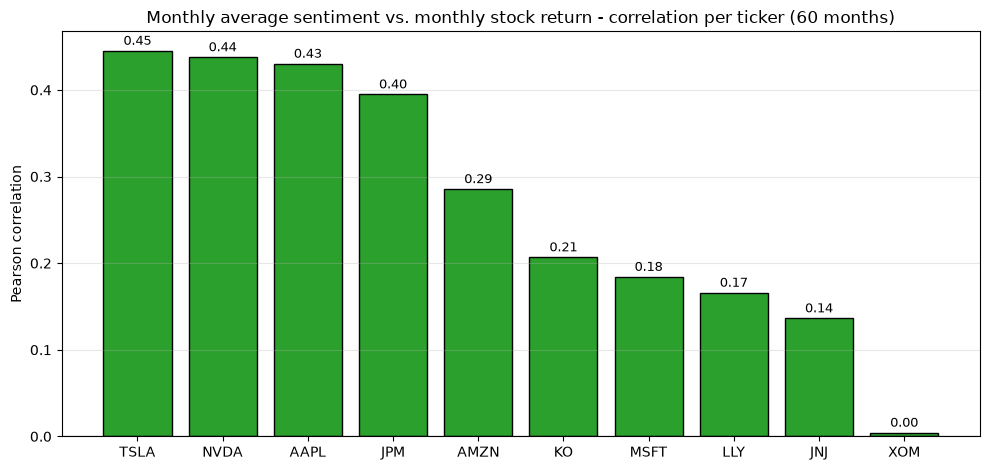

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.8))
colors = ["#2ca02c" if v > 0 else "#d62728" for v in corr["corr_sentiment_vs_return"]]
bars = ax.bar(corr.index, corr["corr_sentiment_vs_return"], color=colors, edgecolor="black")
ax.bar_label(bars, fmt="%.2f", fontsize=9, padding=2)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Pearson correlation")
ax.set_title("Monthly average sentiment vs. monthly stock return - correlation per ticker (60 months)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Chart 3 - Monthly average sentiment vs. monthly return (all tickers)
Each dot is one ticker-month. The black line is a simple least-squares fit across all 600 points.

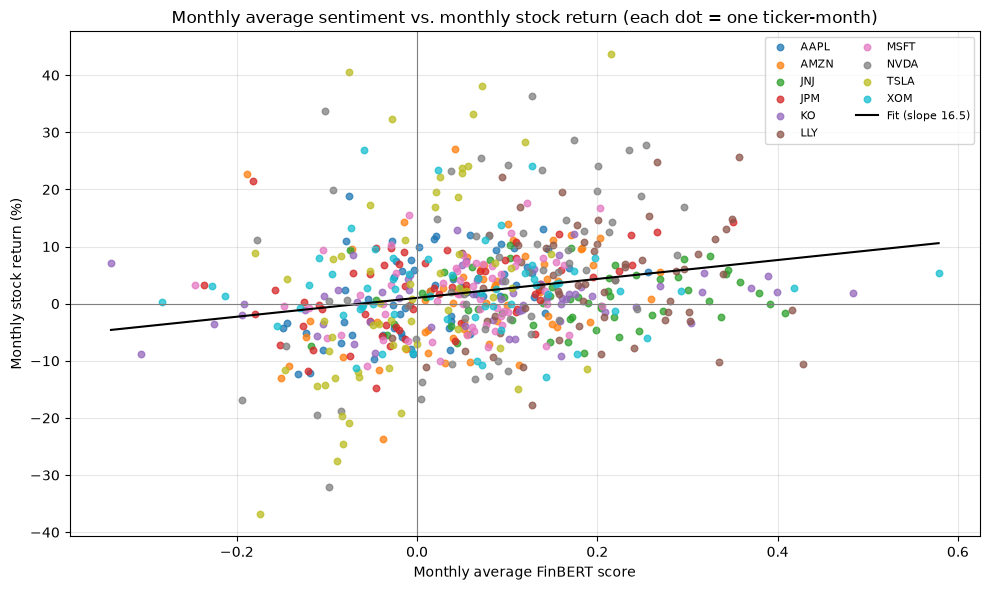

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))
for t, d in monthly.groupby("ticker"):
    ax.scatter(d["avg_sentiment"], d["monthly_return"] * 100, s=22, alpha=0.75, label=t)

slope, intercept = np.polyfit(monthly["avg_sentiment"], monthly["monthly_return"] * 100, 1)
xs = np.linspace(monthly["avg_sentiment"].min(), monthly["avg_sentiment"].max(), 100)
ax.plot(xs, slope * xs + intercept, color="black", linewidth=1.5, label=f"Fit (slope {slope:.1f})")

ax.axhline(0, color="grey", linewidth=0.8)
ax.axvline(0, color="grey", linewidth=0.8)
ax.set_xlabel("Monthly average FinBERT score")
ax.set_ylabel("Monthly stock return (%)")
ax.set_title("Monthly average sentiment vs. monthly stock return (each dot = one ticker-month)")
ax.legend(ncol=2, fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Step 6 - Five findings

**1. On the reaction day, sentiment and returns move in the same direction.** For all articles, the stock's average same-day return is **+0.50%** after positive news, **+0.15%** after neutral news and **-0.18%** after negative news. That is a gap of **0.68 percentage points** between positive and negative news. For comparison, a normal stock-day in the data returns about **+0.11%**. So positive news goes with clearly above-normal days, and negative news goes with below-normal days.

**2. The relationship is stronger for focused articles.** When only articles mentioning **3 or fewer symbols** are kept (53,861 of 102,711 rows), the gap grows to **0.81 percentage points**: **+0.55%** for positive and **-0.26%** for negative. Roundup articles that mention many companies weaken the link, because their tone is often not about the specific stock.

**3. Sentiment has no visible association with the next day's return.** Next-day average returns are almost the same for every category: **+0.12%** negative, **+0.11%** neutral, **+0.10%** positive. These are close to the normal day (**+0.11%**). The positive-minus-negative gap is about zero (**-0.03 pp** for all articles, **-0.002 pp** for focused articles). Whatever the news says, the market reacts on the reaction day itself. The data does not show the price continuing to drift in the direction of the sentiment afterwards.

**4. Month by month, sentiment and returns are positively correlated for all 10 stocks.** The correlation between monthly average sentiment and monthly return is positive for every ticker (average **0.27**, pooled **0.23** across all 600 ticker-months). It is strongest for **TSLA (0.45), NVDA (0.44), AAPL (0.43)** and **JPM (0.40)**, followed by **AMZN (0.29)**. With 60 months, a correlation above about 0.25 is unlikely to come from chance alone (5% level), so these five tickers show a real association.

**5. For the other stocks the link is weak, and it does not depend only on news volume.** **KO (0.21), MSFT (0.18), LLY (0.17), JNJ (0.14)** and **XOM (0.00)** show weak or no monthly correlation. News volume alone does not explain this: MSFT has about 222 articles per month but only 0.18, while JPM has about 61 per month and reaches 0.40. XOM shows no relationship at all, which suggests other factors (for example oil prices) matter more for its returns than news tone.

> **Reminder:** these are associations, not causation. Part of the same-day relationship can also run the other way: news articles are often written *because* a stock moved (for example "Stock X jumps after ..."), so the headline tone reflects the price move, not the other way round.